# TA-07 — Implementasi dan Analisis Simulasi Sistem Dinamik
**Mata Kuliah:** Pemodelan dan Simulasi (Modul 7: Dynamic System Simulation)  
**Studi Kasus:** Pertumbuhan Penduduk Indonesia 1960–2024 dengan Model Logistik  
**Nama / NIM:** Fahriansyah Putra / 301240024 (5-B)

## 1. Formulasi Model Matematika

**Struktur Stock–Flow**

| Elemen | Pada studi kasus ini |
|---|---|
| Stock | Jumlah penduduk $P(t)$ (juta jiwa) |
| Inflow | Pertumbuhan alami $rP$ (kelahiran bersih) |
| Outflow | Hambatan lingkungan $\frac{r}{K}P^2$ (keterbatasan sumber daya) |
| Feedback (R) | Penduduk makin banyak → inflow makin besar → penduduk makin banyak (*reinforcing*) |
| Feedback (B) | Penduduk mendekati $K$ → outflow makin besar → pertumbuhan melambat (*balancing*) |

**Persamaan diferensial (model logistik)**

$$\frac{dP}{dt} = rP\left(1-\frac{P}{K}\right)$$

**Solusi analitik** (dipakai sebagai pembanding akurasi metode numerik):

$$P(t)=\frac{K}{1+\left(\frac{K-P_0}{P_0}\right)e^{-rt}}$$

**Parameter:** $P_0$ = penduduk awal (data tahun 1960), $r$ = laju pertumbuhan intrinsik (per tahun), $K$ = kapasitas dukung (juta jiwa).
$r$ dan $K$ **tidak ditebak**, tetapi dikalibrasi dari data (langkah 3).

**Sumber data:** United Nations, *World Population Prospects* (data tahunan, via Macrotrends): https://www.macrotrends.net/countries/IDN/indonesia/population

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 2. Memuat Data dan Eksplorasi Singkat

In [2]:
df = pd.read_csv("indonesia_population.csv")
df["Population_juta"] = df["Population"] / 1e6      # satuan juta jiwa
df["t"] = df["Year"] - df["Year"].min()              # waktu relatif (tahun ke-0 = 1960)

print("Ukuran dataset  :", df.shape)
print("Missing values  :", int(df.isnull().sum().sum()))
print("Rentang tahun   :", df["Year"].min(), "-", df["Year"].max())
print(df["Population_juta"].describe().round(2))
df.head()

Ukuran dataset  : (65, 4)
Missing values  : 0
Rentang tahun   : 1960 - 2024
count     65.00
mean     186.57
std       59.25
min       88.38
25%      134.52
50%      188.56
75%      237.94
max      279.80
Name: Population_juta, dtype: float64


,Year,Population,Population_juta,t
0,1960,88382881,88.382881,0
1,1961,90816938,90.816938,1
2,1962,93345489,93.345489,2
3,1963,95962527,95.962527,3
4,1964,98675061,98.675061,4


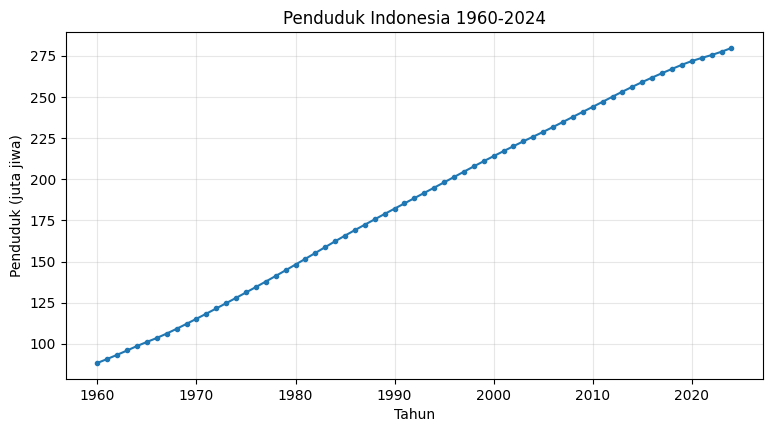

In [3]:
plt.figure(figsize=(9, 4.5))
plt.plot(df["Year"], df["Population_juta"], "o-", ms=3, color="tab:blue")
plt.title("Penduduk Indonesia 1960-2024")
plt.xlabel("Tahun")
plt.ylabel("Penduduk (juta jiwa)")
plt.savefig("figures/01_data_populasi.png", dpi=150, bbox_inches="tight")
plt.show()

**Apakah model logistik masuk akal?** Pada model logistik, laju pertumbuhan relatif $g=\frac{1}{P}\frac{dP}{dt}=r(1-P/K)$ turun **linear** terhadap $P$.
Kita periksa dengan data: hitung $g$ tiap tahun, lalu regresikan terhadap $P$. Garis regresi memberi tebakan awal $r$ (intersep) dan $K$ (titik $g=0$).

Tebakan awal  r0 = 0.0388 per tahun,  K0 = 348.1 juta jiwa


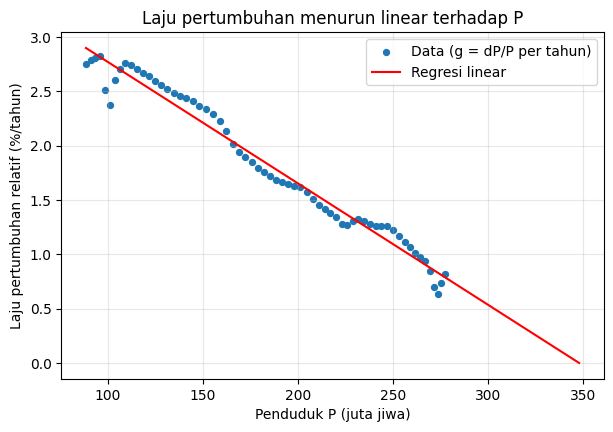

In [4]:
P = df["Population_juta"].values
g = np.diff(P) / P[:-1]                       # laju pertumbuhan relatif per tahun
slope, intercept = np.polyfit(P[:-1], g, 1)    # g = intercept + slope * P
r0 = intercept
K0 = -intercept / slope
print(f"Tebakan awal  r0 = {r0:.4f} per tahun,  K0 = {K0:.1f} juta jiwa")

plt.figure(figsize=(7, 4.5))
plt.scatter(P[:-1], g * 100, s=18, label="Data (g = dP/P per tahun)")
xs = np.linspace(P.min(), K0, 50)
plt.plot(xs, (intercept + slope * xs) * 100, "r-", label="Regresi linear")
plt.xlabel("Penduduk P (juta jiwa)")
plt.ylabel("Laju pertumbuhan relatif (%/tahun)")
plt.title("Laju pertumbuhan menurun linear terhadap P")
plt.legend()
plt.savefig("figures/02_growth_vs_P.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Implementasi Simulasi: Euler, RK4, dan `solve_ivp`

In [5]:
def logistic_model(t, P, r, K):
    """dP/dt = r P (1 - P/K)"""
    return r * P * (1 - P / K)

def logistic_analytic(t, P0, r, K):
    """Solusi analitik model logistik."""
    return K / (1 + ((K - P0) / P0) * np.exp(-r * t))

def euler(f, P0, t_end, h, args=()):
    """Metode Euler: P[i+1] = P[i] + h * f(t[i], P[i])."""
    n = int(round(t_end / h))
    t = np.linspace(0, n * h, n + 1)
    P = np.zeros(n + 1)
    P[0] = P0
    for i in range(n):
        P[i + 1] = P[i] + h * f(t[i], P[i], *args)
    return t, P

def rk4(f, P0, t_end, h, args=()):
    """Runge-Kutta orde 4."""
    n = int(round(t_end / h))
    t = np.linspace(0, n * h, n + 1)
    P = np.zeros(n + 1)
    P[0] = P0
    for i in range(n):
        k1 = f(t[i], P[i], *args)
        k2 = f(t[i] + h / 2, P[i] + h * k1 / 2, *args)
        k3 = f(t[i] + h / 2, P[i] + h * k2 / 2, *args)
        k4 = f(t[i] + h, P[i] + h * k3, *args)
        P[i + 1] = P[i] + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return t, P

def metrik(y_true, y_pred):
    err = y_true - y_pred
    rmse = np.sqrt(np.mean(err ** 2))
    mape = np.mean(np.abs(err) / y_true) * 100
    r2 = 1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    return rmse, mape, r2

**Kalibrasi parameter** $r$ dan $K$ dengan *least squares* terhadap data, dengan $P_0$ = data tahun 1960 dan tebakan awal dari regresi di atas.

In [6]:
P0 = df["Population_juta"].iloc[0]
t_data = df["t"].values.astype(float)
P_data = df["Population_juta"].values

(r_fit, K_fit), _ = curve_fit(lambda t, r, K: logistic_analytic(t, P0, r, K),
                              t_data, P_data, p0=[r0, K0], maxfev=20000)

print(f"P0 (1960)            = {P0:.3f} juta jiwa")
print(f"r hasil kalibrasi    = {r_fit:.5f} per tahun ({r_fit*100:.2f}%/tahun)")
print(f"K hasil kalibrasi    = {K_fit:.2f} juta jiwa")

P0 (1960)            = 88.383 juta jiwa
r hasil kalibrasi    = 0.03856 per tahun (3.86%/tahun)
K hasil kalibrasi    = 350.38 juta jiwa


In [7]:
t_end = t_data.max()

# 1) Euler (h = 1 tahun, sesuai interval data)
t_eu, P_eu = euler(logistic_model, P0, t_end, h=1, args=(r_fit, K_fit))
# 2) RK4 (h = 1 tahun)
t_rk, P_rk = rk4(logistic_model, P0, t_end, h=1, args=(r_fit, K_fit))
# 3) SciPy solve_ivp
sol = solve_ivp(logistic_model, (0, t_end), [P0], args=(r_fit, K_fit),
                t_eval=t_data, rtol=1e-9, atol=1e-9)

hasil = {"Euler (h=1)": P_eu, "RK4 (h=1)": P_rk, "solve_ivp": sol.y[0]}
tabel = pd.DataFrame(
    {nama: metrik(P_data, p) for nama, p in hasil.items()},
    index=["RMSE (juta)", "MAPE (%)", "R2"]
).T
tabel.round(4)

,RMSE (juta),MAPE (%),R2
Euler (h=1),0.8255,0.3929,0.9998
RK4 (h=1),0.7518,0.3720,0.9998
solve_ivp,0.7518,0.3720,0.9998


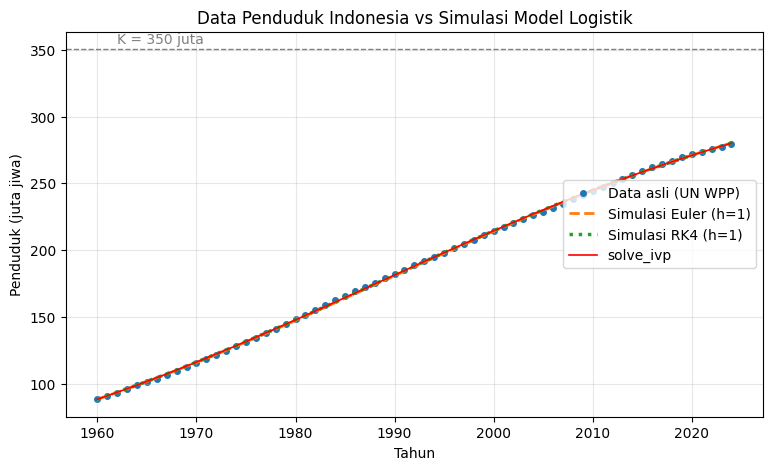

In [8]:
plt.figure(figsize=(9, 5))
plt.scatter(df["Year"], P_data, s=16, color="tab:blue", label="Data asli (UN WPP)")
plt.plot(df["Year"], P_eu, "--", color="tab:orange", lw=2, label="Simulasi Euler (h=1)")
plt.plot(df["Year"], P_rk, ":", color="tab:green", lw=2.5, label="Simulasi RK4 (h=1)")
plt.plot(df["Year"], sol.y[0], color="red", lw=1.2, label="solve_ivp")
plt.axhline(K_fit, color="gray", ls="--", lw=1)
plt.text(1962, K_fit + 4, f"K = {K_fit:.0f} juta", color="gray")
plt.title("Data Penduduk Indonesia vs Simulasi Model Logistik")
plt.xlabel("Tahun")
plt.ylabel("Penduduk (juta jiwa)")
plt.legend(loc="center right")
plt.savefig("figures/03_data_vs_simulasi.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Pengaruh Langkah Waktu $h$ pada Metode Euler

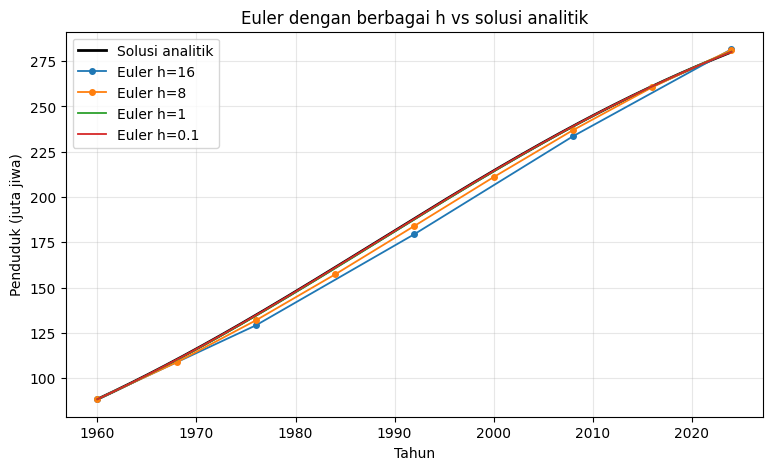

,h (tahun),Jumlah langkah,Galat maks (juta),Galat akhir (juta)
0,16.0,4,8.59942,1.52437
1,8.0,8,4.04897,1.12958
2,1.0,64,0.48001,0.17139
3,0.1,640,0.04763,0.01749


In [9]:
analitik = lambda t: logistic_analytic(t, P0, r_fit, K_fit)
baris = []
plt.figure(figsize=(9, 5))
t_halus = np.linspace(0, t_end, 400)
plt.plot(2024 - t_end + t_halus, analitik(t_halus), "k-", lw=2, label="Solusi analitik")
for h in [16, 8, 1, 0.1]:
    t_h, P_h = euler(logistic_model, P0, t_end, h, args=(r_fit, K_fit))
    galat = np.abs(P_h - analitik(t_h))
    baris.append([h, len(t_h) - 1, galat.max(), galat[-1]])
    plt.plot(1960 + t_h, P_h, "o-" if h >= 8 else "-", ms=4, lw=1.3, label=f"Euler h={h}")
plt.title("Euler dengan berbagai h vs solusi analitik")
plt.xlabel("Tahun")
plt.ylabel("Penduduk (juta jiwa)")
plt.legend()
plt.savefig("figures/04_euler_step_size.png", dpi=150, bbox_inches="tight")
plt.show()

tabel_h = pd.DataFrame(baris, columns=["h (tahun)", "Jumlah langkah", "Galat maks (juta)", "Galat akhir (juta)"])
tabel_h.round(5)

## 5. Eksperimen Skenario *What-If* (Proyeksi 2024 → 2100)

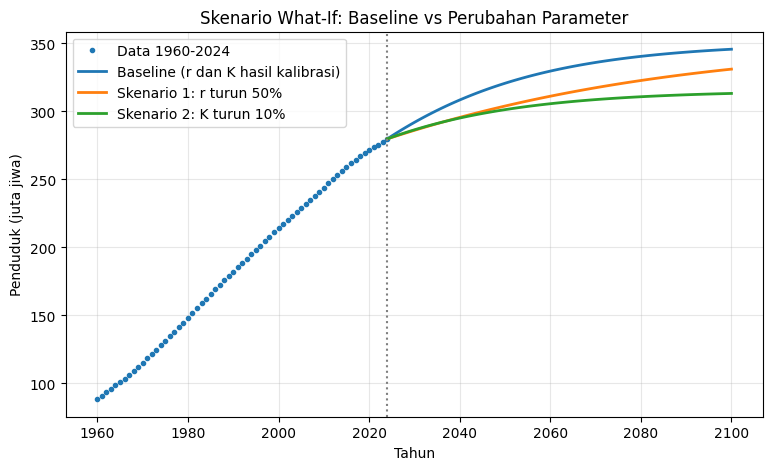

,Skenario,Penduduk 2050 (juta),Penduduk 2100 (juta)
0,Baseline (r dan K hasil kalibrasi),320.7,345.7
1,Skenario 1: r turun 50%,303.9,331.1
2,Skenario 2: K turun 10%,301.3,313.2


In [10]:
P_2024 = P_data[-1]
horizon = 2100 - 2024
t_proj = np.linspace(0, horizon, 77)

skenario = {
    "Baseline (r dan K hasil kalibrasi)": (r_fit, K_fit),
    "Skenario 1: r turun 50%": (0.5 * r_fit, K_fit),
    "Skenario 2: K turun 10%": (r_fit, 0.9 * K_fit),
}

plt.figure(figsize=(9, 5))
plt.plot(df["Year"], P_data, "o", ms=3, color="tab:blue", label="Data 1960-2024")
ringkas = []
for nama, (r_s, K_s) in skenario.items():
    s = solve_ivp(logistic_model, (0, horizon), [P_2024], args=(r_s, K_s),
                  t_eval=t_proj, rtol=1e-9, atol=1e-9)
    plt.plot(2024 + s.t, s.y[0], lw=2, label=nama)
    ringkas.append([nama, s.y[0][26], s.y[0][-1]])
plt.axvline(2024, color="gray", ls=":")
plt.title("Skenario What-If: Baseline vs Perubahan Parameter")
plt.xlabel("Tahun")
plt.ylabel("Penduduk (juta jiwa)")
plt.legend()
plt.savefig("figures/05_skenario_whatif.png", dpi=150, bbox_inches="tight")
plt.show()

tabel_s = pd.DataFrame(ringkas, columns=["Skenario", "Penduduk 2050 (juta)", "Penduduk 2100 (juta)"])
tabel_s.round(1)

## 6. Diagram Stock–Flow

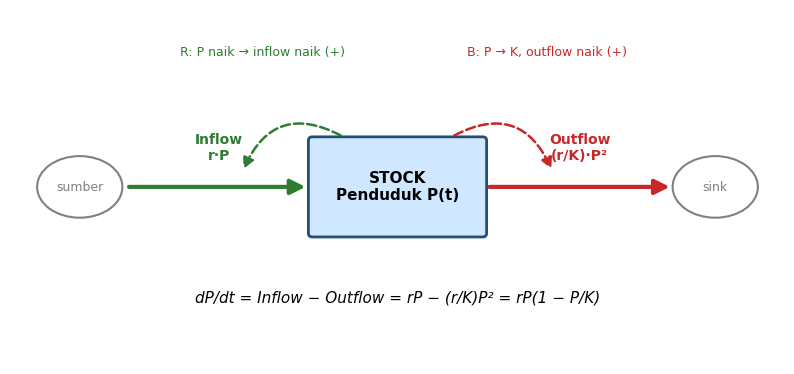

In [11]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Ellipse

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.set_xlim(0, 10); ax.set_ylim(0, 4.6); ax.axis("off")

# Stock
ax.add_patch(FancyBboxPatch((3.9, 1.7), 2.2, 1.2, boxstyle="round,pad=0.05", fc="#cfe8ff", ec="#1f4e79", lw=2))
ax.text(5.0, 2.3, "STOCK\nPenduduk P(t)", ha="center", va="center", fontsize=11, fontweight="bold")
# Source & sink (awan)
for x in (0.9, 9.1):
    ax.add_patch(Ellipse((x, 2.3), 1.1, 0.8, fc="white", ec="gray", lw=1.5))
ax.text(0.9, 2.3, "sumber", ha="center", va="center", fontsize=9, color="gray")
ax.text(9.1, 2.3, "sink", ha="center", va="center", fontsize=9, color="gray")
# Flow
ax.add_patch(FancyArrowPatch((1.5, 2.3), (3.85, 2.3), arrowstyle="-|>", mutation_scale=22, lw=3, color="#2e7d32"))
ax.text(2.7, 2.65, "Inflow\nr·P", ha="center", fontsize=10, color="#2e7d32", fontweight="bold")
ax.add_patch(FancyArrowPatch((6.15, 2.3), (8.55, 2.3), arrowstyle="-|>", mutation_scale=22, lw=3, color="#c62828"))
ax.text(7.35, 2.65, "Outflow\n(r/K)·P²", ha="center", fontsize=10, color="#c62828", fontweight="bold")
# Feedback loops
ax.add_patch(FancyArrowPatch((4.3, 2.95), (3.0, 2.5), connectionstyle="arc3,rad=0.55", arrowstyle="-|>", mutation_scale=16, lw=1.8, color="#2e7d32", ls="--"))
ax.text(2.2, 4.0, "R: P naik → inflow naik (+)", fontsize=9, color="#2e7d32")
ax.add_patch(FancyArrowPatch((5.7, 2.95), (7.0, 2.5), connectionstyle="arc3,rad=-0.55", arrowstyle="-|>", mutation_scale=16, lw=1.8, color="#c62828", ls="--"))
ax.text(5.9, 4.0, "B: P → K, outflow naik (+)", fontsize=9, color="#c62828")
ax.text(5.0, 0.8, "dP/dt = Inflow − Outflow = rP − (r/K)P² = rP(1 − P/K)", ha="center", fontsize=11, style="italic")
plt.savefig("figures/06_stock_flow.png", dpi=150, bbox_inches="tight")
plt.show()